In [1]:
# Sel 1 — hubungkan Drive & muat data
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/Project Data mining/Dataset/Clean_Dataset.csv')
df.head()


Mounted at /content/drive


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [2]:
# Sel 2 — ukuran, tipe data, missing value, duplikat
print("Ukuran data:", df.shape)
df.info()
print("\nMissing value per kolom:\n", df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Ukuran data: (300153, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB

Missing value per kolom:
 Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_tim

In [3]:
# Sel 3 — statistik deskriptif kolom numerik
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [4]:
# Sel 4 — isi kolom kategorikal
for col in ['airline', 'source_city', 'destination_city', 'departure_time',
            'arrival_time', 'stops', 'class']:
    print(f"\n=== {col} ===")
    print(df[col].value_counts())


=== airline ===
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

=== source_city ===
source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

=== destination_city ===
destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

=== departure_time ===
departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

=== arrival_time ===
arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417
Late_Night       14001
Name: count, dtype: int64

=== stops ===
stops
one            250863
zero            36004
two_or

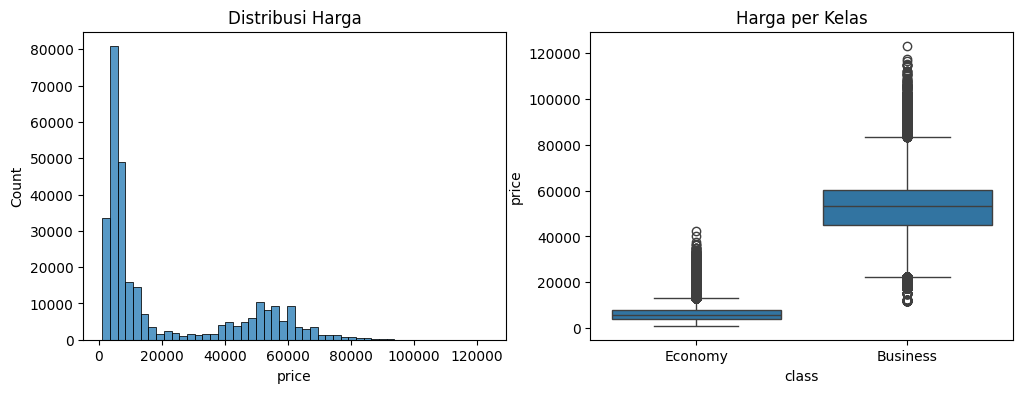

In [5]:
# Sel 5 — distribusi harga
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=ax[0]).set_title('Distribusi Harga')
sns.boxplot(data=df, x='class', y='price', ax=ax[1]).set_title('Harga per Kelas')
plt.show()

## Analisis Pola (lanjutan EDA)
Sel 6–11 menggali pola harga terhadap tiap faktor. Hasilnya menjadi dasar preprocessing dan bahan bab analisis di laporan.

In [6]:
# Sel 6 — cek ulang duplikat TANPA kolom indeks
# (di Sel 2 duplikat = 0 karena 'Unnamed: 0' selalu unik, jadi duplikat asli bisa tersembunyi)
dup = df.drop(columns=['Unnamed: 0']).duplicated().sum()
print("Duplikat sebenarnya:", dup)

Duplikat sebenarnya: 0


In [7]:
# Sel 7 — maskapai mana yang punya kelas Business?
pd.crosstab(df['airline'], df['class'])

class,Business,Economy
airline,,
AirAsia,0,16098
Air_India,32898,47994
GO_FIRST,0,23173
Indigo,0,43120
SpiceJet,0,9011
Vistara,60589,67270


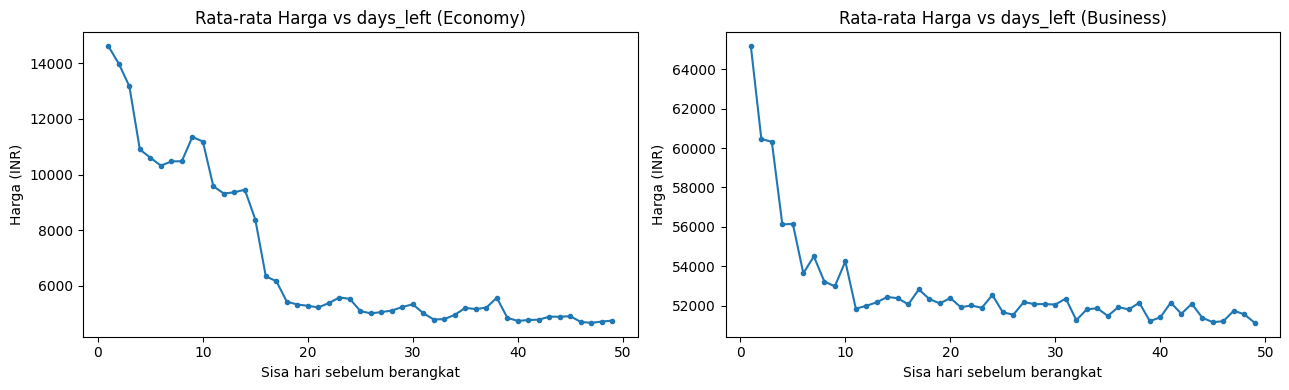

In [8]:
# Sel 8 — harga vs sisa hari sebelum berangkat (rata-rata per kelas)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, kelas in enumerate(['Economy', 'Business']):
    d = df[df['class'] == kelas].groupby('days_left')['price'].mean()
    ax[i].plot(d.index, d.values, marker='o', markersize=3)
    ax[i].set_title(f'Rata-rata Harga vs days_left ({kelas})')
    ax[i].set_xlabel('Sisa hari sebelum berangkat'); ax[i].set_ylabel('Harga (INR)')
plt.tight_layout(); plt.show()

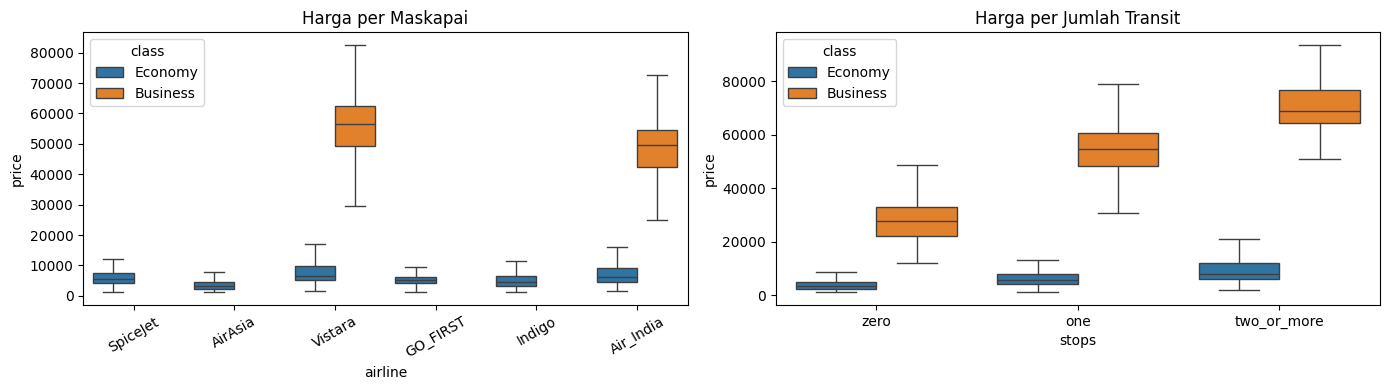

In [9]:
# Sel 9 — harga per maskapai dan per jumlah transit (dipisah per kelas)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x='airline', y='price', hue='class', ax=ax[0], showfliers=False)
ax[0].set_title('Harga per Maskapai'); ax[0].tick_params(axis='x', rotation=30)
sns.boxplot(data=df, x='stops', y='price', hue='class', ax=ax[1], showfliers=False,
            order=['zero', 'one', 'two_or_more'])
ax[1].set_title('Harga per Jumlah Transit')
plt.tight_layout(); plt.show()

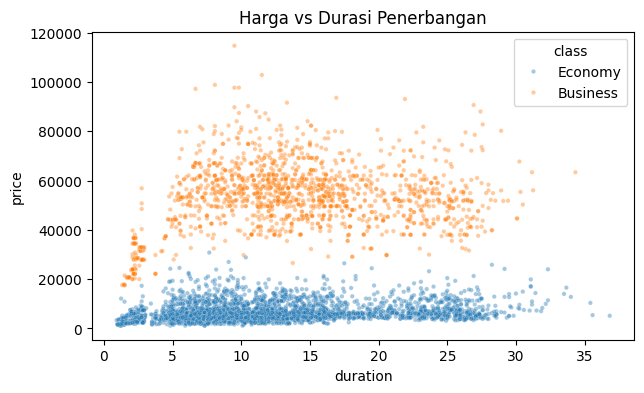

           duration  days_left  price
duration      1.000     -0.039  0.204
days_left    -0.039      1.000 -0.092
price         0.204     -0.092  1.000


In [10]:
# Sel 10 — harga vs durasi (sampel 5.000 baris agar plot ringan) + korelasi numerik
sampel = df.sample(5000, random_state=42)
plt.figure(figsize=(7, 4))
sns.scatterplot(data=sampel, x='duration', y='price', hue='class', alpha=0.4, s=10)
plt.title('Harga vs Durasi Penerbangan'); plt.show()

print(df[['duration', 'days_left', 'price']].corr().round(3))

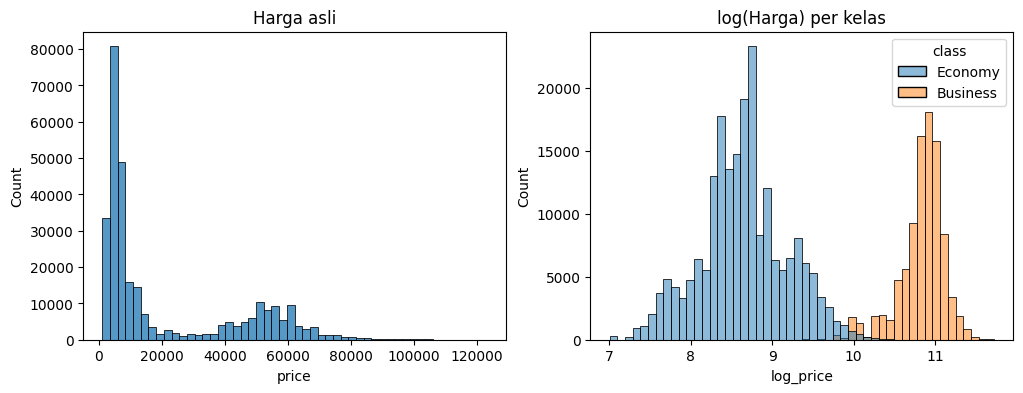

In [11]:
# Sel 11 — efek transformasi log pada harga
import numpy as np
df['log_price'] = np.log(df['price'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=ax[0]).set_title('Harga asli')
sns.histplot(data=df, x='log_price', hue='class', bins=50, ax=ax[1]).set_title('log(Harga) per kelas')
plt.show()
df = df.drop(columns=['log_price'])  # hanya untuk eksplorasi, transformasi resmi dilakukan di notebook preprocessing